In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Load Wine dataset
wine = load_wine()

# Create DataFrame
df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

# Add target column
df['target'] = wine.target

# Display first five rows
print("First five rows:")
display(df.head())

# Dataset information
print("\nDataset Information:")
print(df.info())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


In [ ]:
# Separate independent and dependent variables
X = df.drop('target', axis=1)
y = df['target']

print("Independent Features:")
display(X.head())

print("\nTarget Classes:")
print(y.unique())

print("\nOriginal Dataset Shape:", X.shape)

Independent Features:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Target Classes:
[0 1 2]

Original Dataset Shape: (178, 13)


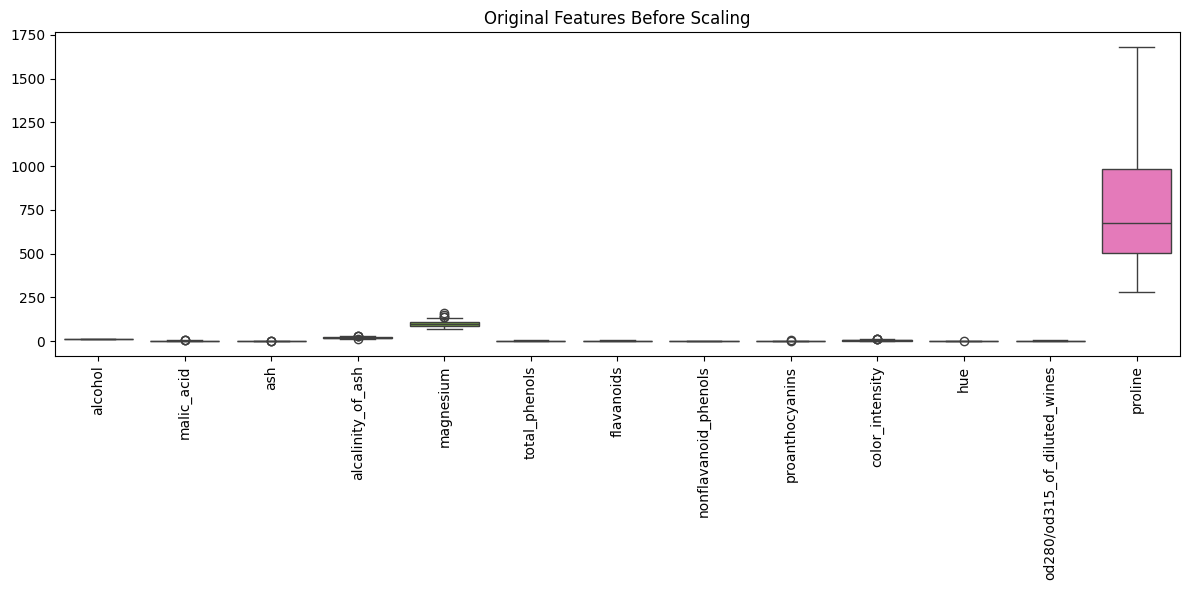

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=X)

plt.title("Original Features Before Scaling")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
# Create MinMaxScaler
normalizer = MinMaxScaler()

# Apply normalization
X_normalized = normalizer.fit_transform(X)

# Convert into DataFrame
df_normalized = pd.DataFrame(
    X_normalized,
    columns=X.columns
)

print("Normalized Dataset:")
display(df_normalized.head())

print("\nMinimum Values:")
print(df_normalized.min().round(2))

print("\nMaximum Values:")
print(df_normalized.max().round(2))

Normalized Dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,0.842105,0.191700,0.572193,0.257732,0.619565,0.627586,0.573840,0.283019,0.593060,0.372014,0.455285,0.970696,0.561341
1,0.571053,0.205534,0.417112,0.030928,0.326087,0.575862,0.510549,0.245283,0.274448,0.264505,0.463415,0.780220,0.550642
2,0.560526,0.320158,0.700535,0.412371,0.336957,0.627586,0.611814,0.320755,0.757098,0.375427,0.447154,0.695971,0.646933
3,0.878947,0.239130,0.609626,0.319588,0.467391,0.989655,0.664557,0.207547,0.558360,0.556314,0.308943,0.798535,0.857347
4,0.581579,0.365613,0.807487,0.536082,0.521739,0.627586,0.495781,0.490566,0.444795,0.259386,0.455285,0.608059,0.325963



Minimum Values:
alcohol                         0.0
malic_acid                      0.0
ash                             0.0
alcalinity_of_ash               0.0
magnesium                       0.0
total_phenols                   0.0
flavanoids                      0.0
nonflavanoid_phenols            0.0
proanthocyanins                 0.0
color_intensity                 0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                         0.0
dtype: float64

Maximum Values:
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline                         1.0
dtype: float64


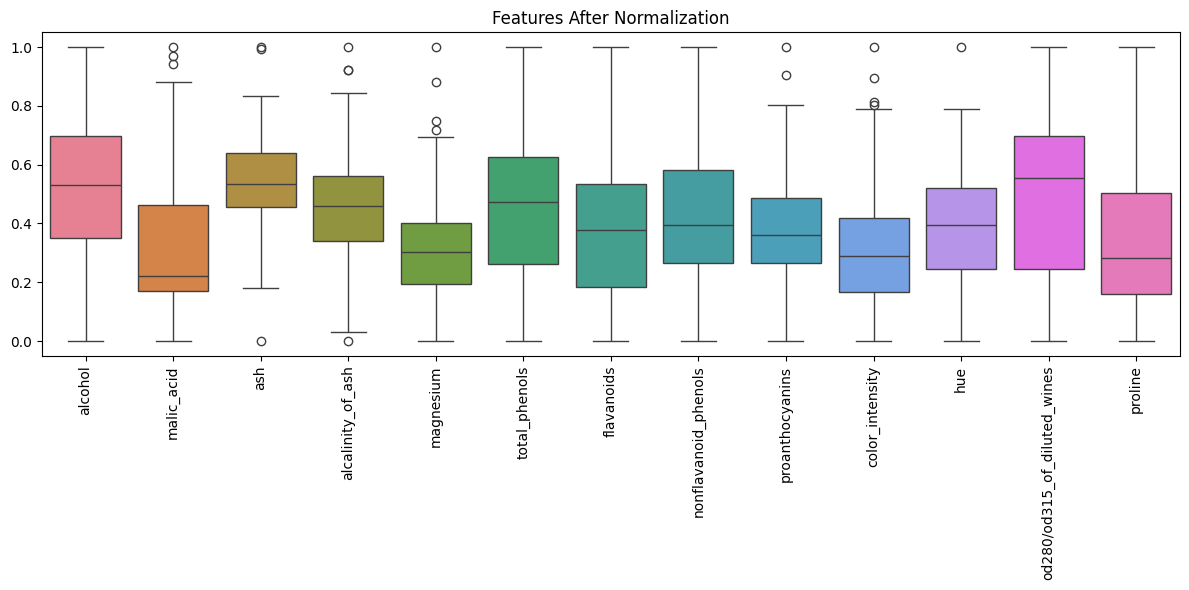

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_normalized)

plt.title("Features After Normalization")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
# Create StandardScaler
standardizer = StandardScaler()

# Apply standardization
X_standardized = standardizer.fit_transform(X)

# Convert into DataFrame
df_standardized = pd.DataFrame(
    X_standardized,
    columns=X.columns
)

print("Standardized Dataset:")
display(df_standardized.head())

print("\nMean of Features:")
print(df_standardized.mean().round(2))

print("\nStandard Deviation:")
print(df_standardized.std().round(2))

Standardized Dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874



Mean of Features:
alcohol                         0.0
malic_acid                      0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                  -0.0
flavanoids                      0.0
nonflavanoid_phenols           -0.0
proanthocyanins                -0.0
color_intensity                -0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64

Standard Deviation:
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline                         1.0
dtype: fl

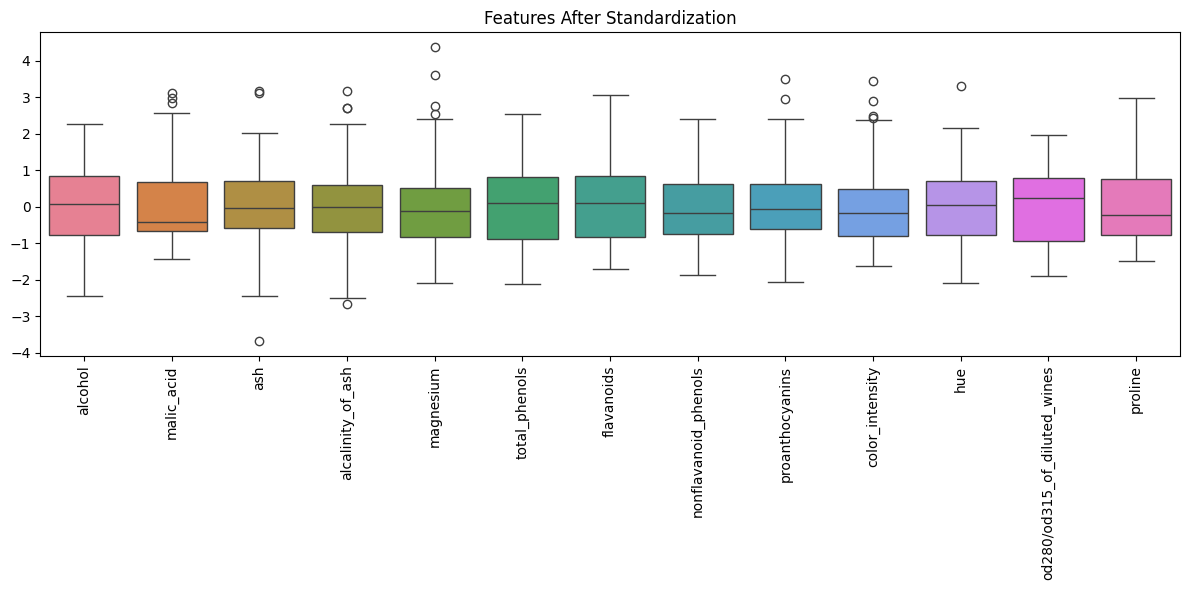

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_standardized)

plt.title("Features After Standardization")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Method': [
        'Original Data',
        'Normalized Data',
        'Standardized Data'
    ],

    'Minimum Value': [
        X.min().min(),
        df_normalized.min().min(),
        df_standardized.min().min()
    ],

    'Maximum Value': [
        X.max().max(),
        df_normalized.max().max(),
        df_standardized.max().max()
    ],

    'Average Value': [
        X.mean().mean(),
        df_normalized.mean().mean(),
        df_standardized.mean().mean()
    ]
})

print("Comparison of Scaling Techniques:")
display(comparison.round(3))

Comparison of Scaling Techniques:


,Method,Minimum Value,Maximum Value,Average Value
0,Original Data,0.130,1680.000,69.134
1,Normalized Data,0.000,1.000,0.408
2,Standardized Data,-3.679,4.371,0.000


In [ ]:
# Apply PCA on standardized data
pca = PCA(n_components=2)

# Transform data into 2 principal components
X_pca = pca.fit_transform(X_standardized)

# Create DataFrame
df_pca = pd.DataFrame(
    X_pca,
    columns=['Principal Component 1',
             'Principal Component 2']
)

print("PCA Transformed Dataset:")
display(df_pca.head())

print("\nOriginal Dimensions:", X.shape)
print("Reduced Dimensions:", X_pca.shape)

PCA Transformed Dataset:


,Principal Component 1,Principal Component 2
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831



Original Dimensions: (178, 13)
Reduced Dimensions: (178, 2)


In [ ]:
# Display explained variance
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

# Total explained variance
total_variance = sum(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:",
      round(total_variance * 100, 2), "%")

Explained Variance Ratio:
[0.36198848 0.1920749 ]

Total Explained Variance: 55.41 %


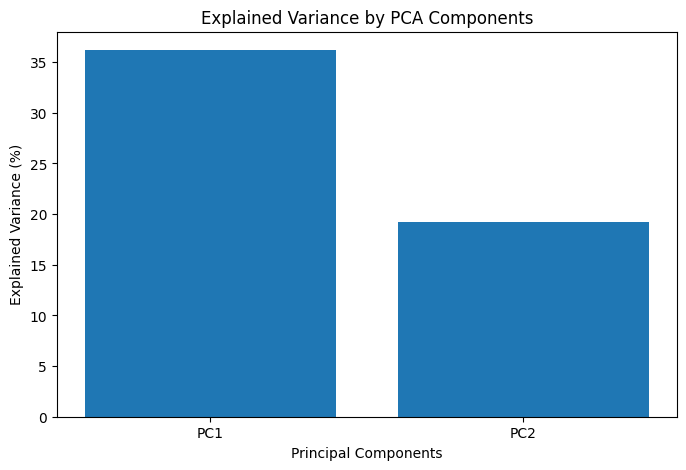

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    ['PC1', 'PC2'],
    pca.explained_variance_ratio_ * 100
)

plt.ylabel("Explained Variance (%)")
plt.xlabel("Principal Components")

plt.title("Explained Variance by PCA Components")

plt.show()

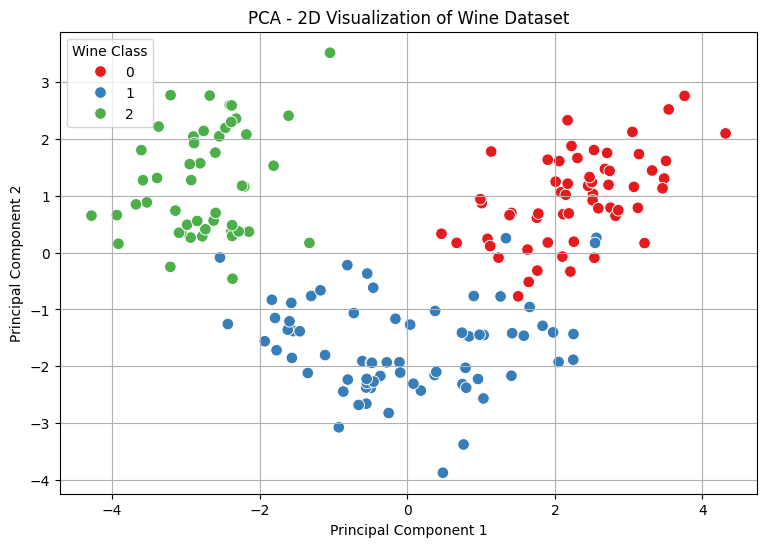

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=y,
    palette='Set1',
    s=70
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA - 2D Visualization of Wine Dataset")

plt.legend(title="Wine Class")
plt.grid(True)

plt.show()

In [ ]:
# Apply PCA with 95% variance retention
pca_95 = PCA(n_components=0.95)

X_pca_95 = pca_95.fit_transform(X_standardized)

print("Original Number of Features:", X.shape[1])

print("Reduced Number of Features:", X_pca_95.shape[1])

print("\nExplained Variance Retained:",
      round(sum(pca_95.explained_variance_ratio_) * 100, 2),
      "%")

Original Number of Features: 13
Reduced Number of Features: 10

Explained Variance Retained: 96.17 %


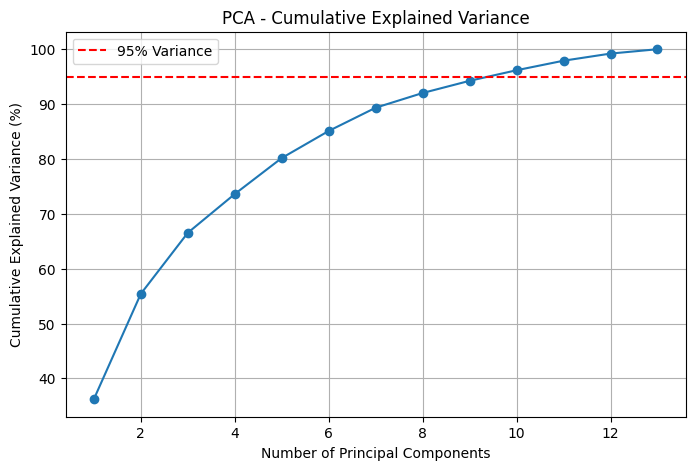

In [ ]:
# PCA with all components
pca_all = PCA()
pca_all.fit(X_standardized)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca_all.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker='o'
)

plt.axhline(
    y=95,
    color='red',
    linestyle='--',
    label='95% Variance'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")

plt.title("PCA - Cumulative Explained Variance")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
dimension_comparison = pd.DataFrame({
    'Dataset': [
        'Original Dataset',
        'PCA (2 Components)',
        'PCA (95% Variance)'
    ],

    'Number of Features': [
        X.shape[1],
        X_pca.shape[1],
        X_pca_95.shape[1]
    ]
})

print("Dimensionality Reduction Comparison:")
display(dimension_comparison)

Dimensionality Reduction Comparison:


,Dataset,Number of Features
0,Original Dataset,13
1,PCA (2 Components),2
2,PCA (95% Variance),10


In [ ]:
print("FINAL RESULT")
print("============")

print("Original Dataset Features:", X.shape[1])

print("\nNormalization:")
print("Data scaled between 0 and 1.")

print("\nStandardization:")
print("Features transformed to approximately")
print("zero mean and unit standard deviation.")

print("\nPCA:")
print("Original Dimensions:", X.shape[1])
print("Reduced Dimensions (2 Components):", X_pca.shape[1])

print("Explained Variance:",
      round(total_variance * 100, 2), "%")

print("\nPCA with 95% Variance:")
print("Reduced Dimensions:", X_pca_95.shape[1])

print("\nFeature Engineering and PCA completed successfully!")

FINAL RESULT
Original Dataset Features: 13

Normalization:
Data scaled between 0 and 1.

Standardization:
Features transformed to approximately
zero mean and unit standard deviation.

PCA:
Original Dimensions: 13
Reduced Dimensions (2 Components): 2
Explained Variance: 55.41 %

PCA with 95% Variance:
Reduced Dimensions: 10

Feature Engineering and PCA completed successfully!
